# Лабораторная работа 1. Иерархический кластерный анализ
**Вариант 2:** Economics of Cities.

Данные: экономические условия в 48 городах мира в 1991 году.
* `Work` --- среднее число рабочих часов в год;
* `Price` --- индекс цен на товары и услуги (Цюрих = 100);
* `Salary` --- индекс почасовой зарплаты после налогов (Цюрих = 100).

## 1. Загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

DATA_PATH = "Econom_Cities_data.csv"
FEATURES = ["Work", "Price", "Salary"]  # признаки для кластеризации

In [2]:
import os
if not os.path.exists(DATA_PATH):
    from google.colab import files
    files.upload()   # выбрать Econom_Cities_data.csv

In [3]:
# разделитель ';', десятичная запятая, пропуски как -9999
df_raw = pd.read_csv(DATA_PATH, sep=";", decimal=",", na_values=[-9999])
print("Размер:", df_raw.shape)

print(df_raw.isna().sum()) # где пропуски
df_raw[df_raw[FEATURES].isna().any(axis=1)] #какие города

Размер: (48, 4)
City      0
Work      2
Price     0
Salary    2
dtype: int64


,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN


In [4]:
df = df_raw.dropna(subset=FEATURES) # убираем города с пропусками
df = df.reset_index(drop=True).copy()
print("Осталось городов:", len(df))

Осталось городов: 46


## 2. Стандартизация

Признаки имеют разный масштаб: `Work` измеряется тысячами, `Price` и `Salary` --- десятками. Расстояние между городами считается по всем признакам сразу, поэтому без масштабирования `Work` полностью доминировал бы. Применяем z-стандартизацию: из значения вычитаем среднее и делим на стандартное отклонение.

In [5]:
X = StandardScaler().fit_transform(df[FEATURES])
print("Форма:", X.shape)

print("Средние:", X.mean(axis=0).round(6), " СКО:", X.std(axis=0).round(6))   # ожидаем 0 и 1

Форма: (46, 3)
Средние: [ 0. -0.  0.]  СКО: [1. 1. 1.]


## 3. Иерархическая кластеризация и дендрограмма
Расстояние между городами --- евклидово.

Расстояние между кластерами --- метод Уорда.

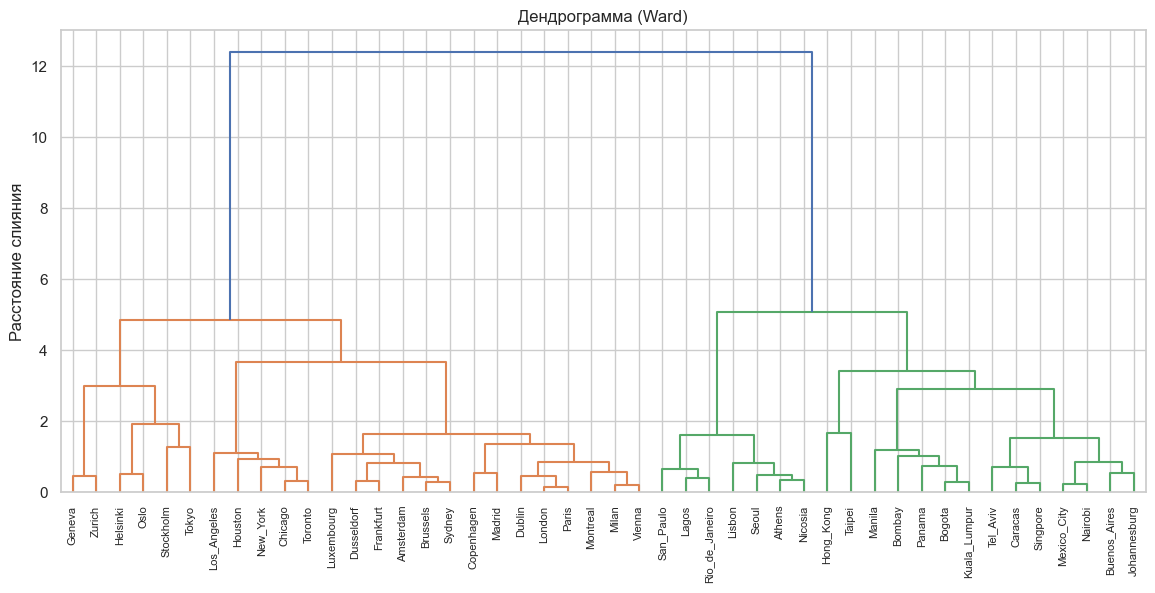

In [6]:
# строим иерархию слияний
Z = linkage(X, method="ward", metric="euclidean")


# Строитм дендрограмму
def plot_dendrogram(Z, labels, threshold=None, title="Дендрограмма (Ward)"):
    """Строит дендрограмму. Если задан threshold, рисует линию отсечения и красит кластеры"""
    plt.figure(figsize=(14, 6))
    dendrogram(Z, labels=labels, color_threshold=threshold)
    if threshold is not None:
        plt.axhline(threshold, color="k", linestyle="--", linewidth=1)
    plt.title(title); plt.ylabel("Расстояние слияния")
    plt.show()

plot_dendrogram(Z, df["City"].values)

## 4. Выбор числа кластеров

Строим график "Каменистая осыпь" (локоть) для определения, на какое кол-во кластеров разбиваем:

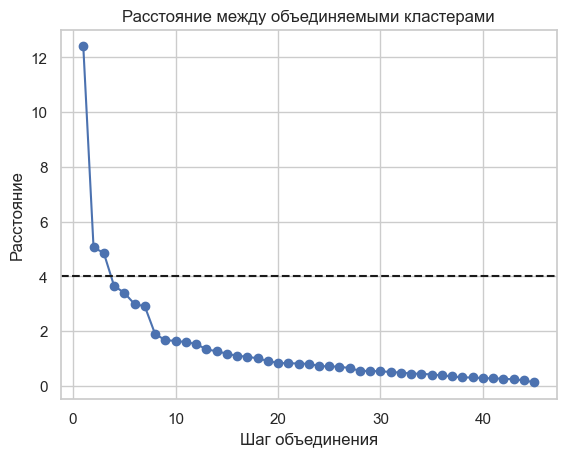

In [7]:
dist = Z[:, 2] # берем расстояния между кластерами перед слияниями
dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1)
plt.plot(idxs, dist_rev, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')
plt.axhline(4, c='k', linestyle='dashed') # отсекаем на расстоянии = 4 и получаем при этом 4 кластера

* Самый большой скачок высоты слияния --- при последнем объединении 2 -> 1; на самом верхнем уровне в данных две крупные группы (богатые и бедные города). Но два кластера --- слишком грубое деление.
* Следующие слияния 3 -> 2 и 4 -> 3 близки между собой, а дальше высота падает (5 -> 4): после четырёх кластеров начинается мелкое дробление. Поэтому разумно остановиться на k = 4.
* Выбираем k = 4: оно выделяет отдельную группу "сверхдорогих" городов и сохраняет группу с очень длинным рабочим годом.

На дендрограмме для k = 4 линия отсечения должна проходить по высоте между 3 и 4 точками --- берём h = 4.

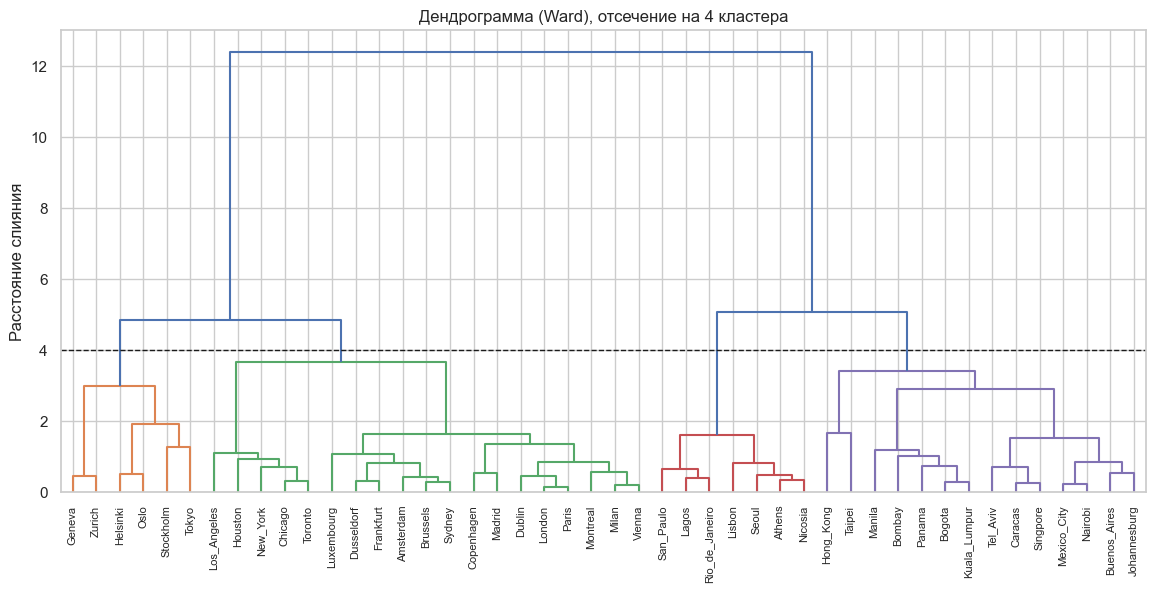

In [8]:
plot_dendrogram(Z, df["City"].values, threshold=4, title="Дендрограмма (Ward), отсечение на 4 кластера")

## 5. Разбиение на кластеры

In [9]:
# Останавливаем объединение, когда расстояние между кластерами превысит 4
df['cluster'] = fcluster(Z, 4, criterion='distance')
df

,City,Work,Price,Salary,cluster
0,Amsterdam,1714.0,65.6,49.0,2
1,Athens,1792.0,53.8,30.4,3
2,Bogota,2152.0,37.9,11.5,4
3,Bombay,2052.0,30.3,5.3,4
4,Brussels,1708.0,73.8,50.5,2
5,Buenos_Aires,1971.0,56.1,12.5,4
6,Caracas,2041.0,61.0,10.9,4
7,Chicago,1924.0,73.9,61.9,2
8,Copenhagen,1717.0,91.3,62.9,2
9,Dublin,1759.0,76.0,41.4,2


In [10]:
# Сколько городов в каждом кластере
df.groupby('cluster').size()

cluster
1     6
2    19
3     7
4    14
dtype: int64

In [11]:
# Кластер и города в нем:
for c in range(1, 5):
  print(f"Кластер {c}")
  print(df[df['cluster']==c].City.values)
  print()

Кластер 1
['Geneva' 'Helsinki' 'Oslo' 'Stockholm' 'Tokyo' 'Zurich']

Кластер 2
['Amsterdam' 'Brussels' 'Chicago' 'Copenhagen' 'Dublin' 'Dusseldorf'
 'Frankfurt' 'Houston' 'London' 'Los_Angeles' 'Luxembourg' 'Madrid'
 'Milan' 'Montreal' 'New_York' 'Paris' 'Sydney' 'Toronto' 'Vienna']

Кластер 3
['Athens' 'Lagos' 'Lisbon' 'Nicosia' 'Rio_de_Janeiro' 'San_Paulo' 'Seoul']

Кластер 4
['Bogota' 'Bombay' 'Buenos_Aires' 'Caracas' 'Hong_Kong' 'Johannesburg'
 'Kuala_Lumpur' 'Manila' 'Mexico_City' 'Nairobi' 'Panama' 'Singpore'
 'Taipei' 'Tel_Aviv']



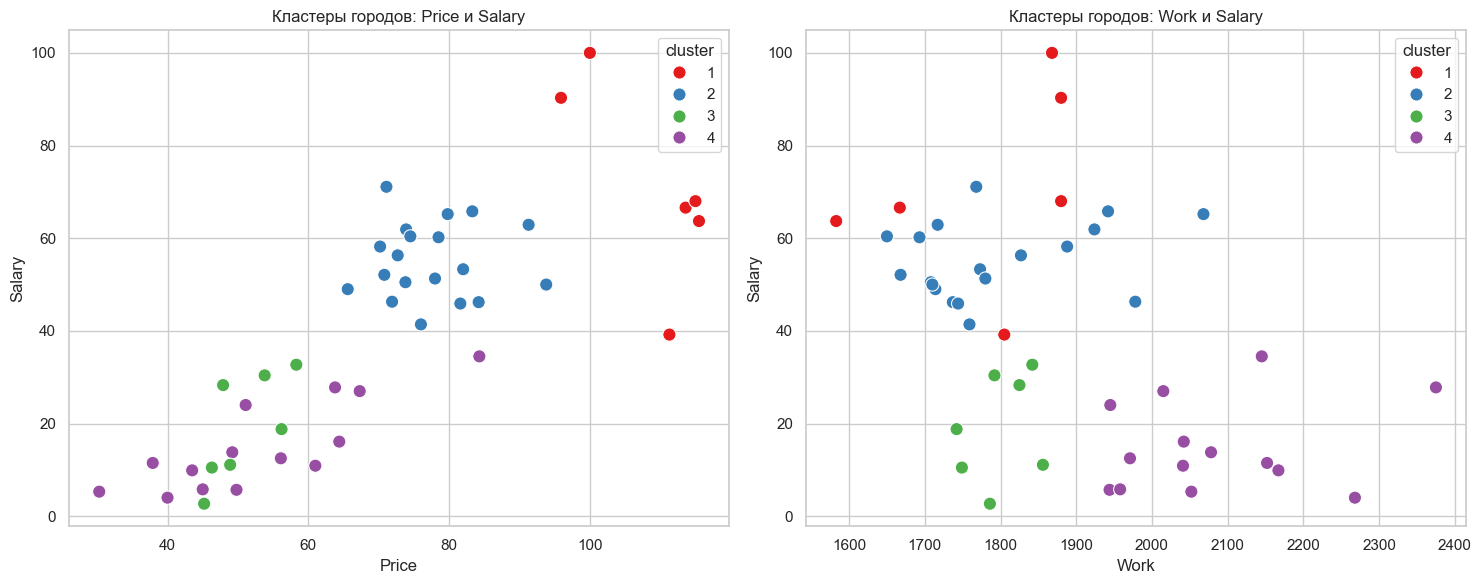

In [12]:
# цвет точки --- номер кластера
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (a, b) in zip(axes, [("Price", "Salary"), ("Work", "Salary")]):
    sns.scatterplot(data=df, x=a, y=b, hue="cluster", palette="Set1", s=90, ax=ax)
    ax.set_title(f"Кластеры городов: {a} и {b}")
plt.tight_layout(); plt.show()

## 6. Интерпретация

In [13]:
# Средние значения признаков по кластерам (в исходных единицах) и размеры кластеров
profile = df.groupby("cluster")[FEATURES].mean().round(1)
profile["Cities count"] = df["cluster"].value_counts().sort_index()
profile

,Work,Price,Salary,Cities count
cluster,,,,
1,1780.5,108.6,71.3,6
2,1792.0,77.5,55.2,19
3,1798.9,50.9,19.2,7
4,2082.4,53.1,14.9,14


Опираясь на средние значения:

| Кластер | Work | Price | Salary | Города | Название |
|---|---|---|---|---|---|
| 1 (6) | ~ 1780 | ~ 109 | ~ 71 | Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich | Сверхдорогие города |
| 2 (19) | ~ 1792 | ~ 78 | ~ 55 | Amsterdam, Brussels, Chicago, Copenhagen, Dublin, etc. | Развитые города |
| 3 (7) | ~ 1799 | ~ 51 | ~ 19 | Athens, Lagos, Lisbon, Nicosia, Rio_de_Janeiro, etc. | Дешёвые города с обычной нагрузкой |
| 4 (14) | ~ 2082 | ~ 53 | ~ 15 | Bogota, Bombay, Buenos_Aires, Caracas, Hong_Kong, etc. | Дешёвые города с длинным рабочим годом |

Чем выше цены и зарплаты, тем меньше рабочих часов. Кластеры 3 и 4 почти не различаются по ценам и зарплатам, но отличаются по рабочему времени примерно на 280 часов в год.

## 7. Выводы

1. Проведён иерархический кластерный анализ 46 городов (Cairo и Jakarta исключены из-за пропусков).
2. Признаки стандартизованы, чтобы `Work` с большим масштабом не доминировал в расстоянии.
3. Использовано евклидово расстояние и метод Уорда. Число кластеров выбрано по дендрограмме и локтю: после четырёх кластеров высота слияния заметно падает.
4. Получено 4 группы: сверхдорогие города, развитые города, дешёвые города с обычной нагрузкой и дешёвые города с длинным рабочим годом.
5. Чем выше цены и зарплаты, тем меньше рабочих часов.